# SpykProps — one-image reproduction: spike segmentation, length, spikelet count

**Paper:** Joan Barreto Ortiz et al., *SpykProps: an imaging pipeline to quantify architecture in unilateral grass inflorescences*, **Plant Methods 19:125 (2023)**, doi:[10.1186/s13007-023-01104-z](https://doi.org/10.1186/s13007-023-01104-z), PMCID PMC10644492.
**Author code:** [github.com/joanmanbar/SpykProps](https://github.com/joanmanbar/SpykProps) pinned at commit `19e8f6ef8c6cdd52f416a9d3ed91b4ce99099b5c` (HEAD, 2023-05-16).
**Data:** [hdl:11299/256105](https://hdl.handle.net/11299/256105) — "Input data and images collected from TROE and Roseau in 2020 and 2021 for SpykProps project", **CC0 1.0**, hosted on UMN Conservancy (the DRUM host `drum.lib.umn.edu` was retired; the handle now resolves there).

**Scope (partial demonstration):** run the authors' own pipeline on **one** original 600-dpi scanner image —
(1) spike segmentation by red-channel threshold after 50% rescale, (2) spike length by the paper's four methods
(bounding box, convex hull, Zhang–Suen skeleton, medial axis), (3) spikelet counting by distance-transform watershed.
**Not covered:** EFD/color descriptor tables, batch CSV export, PCA, and the caret machine-learning prediction phases.

**Execution status:** this notebook was fully executed on a standard Colab **CPU** runtime; the saved outputs below come from that run. No GPU is used anywhere (the pipeline is classical OpenCV/scikit-image; no trained weights exist).

*日本語:* このノートブックは、多年生ライグラスの穂画像1枚（600 dpiスキャン）に対し、著者自身の SpykProps パイプライン（赤チャネル閾値による穂セグメンテーション、4手法の穂長推定、距離変換 watershed による小穂計数）を実行する部分再現デモです。CPU のみで動作し、学習済み重みは不要です。記述子全量・機械学習フェーズは対象外です。

**AI-assistance note / AI利用について:** This notebook was authored by an AI assistant for reproduction purposes; it calls the **authors' own pinned code** with one documented compatibility patch (see below). It is not author-endorsed, and a one-image run does not verify the paper's dataset-level accuracy.


## 1. Runtime selection & Run all

**Select:** `Runtime` → `Change runtime type` → **CPU** (standard). A GPU is unnecessary: the author pipeline is classical computer vision (`cv2`/`scikit-image`/`scipy`), with no `torch` and no CUDA operations.

**Run all** downloads ≈100–110 MB (one scanner TIFF extracted from the pinned dataset zip via HTTP range requests — the full 3.8 GB archive is **not** downloaded), plus the 56 KB author module and two small pip packages. Expect roughly 10–15 minutes end to end on the free CPU tier.

*日本語:* 「ランタイム」→「ランタイムのタイプを変更」で **CPU** を選択してください（GPU 不要）。「すべてのセルを実行」で、データセットZIPから必要なTIFF 1枚のみ（約100 MB）をHTTPレンジリクエストで取得します。


In [ ]:
import platform, sys

print("Python", sys.version.split()[0], "on", platform.machine())

import numpy as np
import pandas as pd
import scipy, skimage, cv2, matplotlib, PIL
import matplotlib.pyplot as plt
for m in (np, pd, scipy, skimage, cv2, matplotlib, PIL):
    print(f"{m.__name__:<12}", getattr(m, "__version__", "?"))

Python 3.13.16 on x86_64


numpy        2.1.3
pandas       2.2.3
scipy        1.16.3
skimage      0.25.2
cv2          5.0.0
matplotlib   3.10.0
PIL          11.3.0


### Install the two packages the author stack needs beyond Colab's preinstalls

`remotezip` reads members of a remote ZIP via HTTP `Range` requests (so only the chosen
TIFF's bytes are transferred). `spatial_efd==1.2.1` is imported at the top of the
authors' `SpykFunctions.py` and is tiny. `cv2`, `scikit-image`, `scipy`, `pandas`,
`matplotlib`, `PIL`, `seaborn`, `imageio` are already present in Colab (versions printed
above).

*日本語:* 著者コードが必要とする `remotezip`（リモートZIPの部分取得）と `spatial_efd`（小容量）のみ追加インストールします。

In [ ]:
%pip install -q remotezip spatial_efd==1.2.1

import remotezip, spatial_efd
print("remotezip", remotezip.__version__ if hasattr(remotezip, "__version__") else "installed")
print("spatial_efd", getattr(spatial_efd, "__version__", "installed"))

remotezip installed
spatial_efd installed


### Fetch the authors' pinned `SpykFunctions.py` and verify its git-blob hash

We download the exact file at the pinned commit from `raw.githubusercontent.com` and
verify it against the git blob SHA-1 recorded from the repository tree
(`e1f3ea77f7940c2dc6e0fc7508a2f9827c9ec272`). The author driver `SpykBatch.py` parses
`argparse` and redirects `stdout` at module level, so it cannot be imported; instead we
call the authors' functions directly and replicate the per-image/per-spike loop exactly
as written in `SpykBatch.py` lines 177–304.

*日本語:* 著者の `SpykFunctions.py` を固定コミットから取得し、git blob SHA-1 で完全性を検証します。`SpykBatch.py` は import できない構造のため、著者の関数を直接呼び出し、ドライバの処理手順を忠実に再現します。

In [ ]:
import hashlib, pathlib, sys, urllib.request

COMMIT = "19e8f6ef8c6cdd52f416a9d3ed91b4ce99099b5c"
EXPECTED_BLOB_SHA1 = "e1f3ea77f7940c2dc6e0fc7508a2f9827c9ec272"  # SpykFunctions.py git blob at this commit
url = f"https://raw.githubusercontent.com/joanmanbar/SpykProps/{COMMIT}/SpykFunctions.py"
raw = urllib.request.urlopen(url, timeout=120).read()

blob_sha1 = hashlib.sha1(b"blob %d\0" % len(raw) + raw).hexdigest()
assert blob_sha1 == EXPECTED_BLOB_SHA1, f"pinned author code hash mismatch: {blob_sha1}"

# Single compatibility patch (behavior-preserving): scikit-image >= 1.0 removed the
# `multichannel=` keyword of skimage.transform.rescale; `channel_axis=-1` is the
# documented replacement used for the same RGB input.
patched = raw.decode("utf-8").replace("multichannel=True", "channel_axis=-1")
n_patches = raw.decode("utf-8").count("multichannel=True")

dest = pathlib.Path("/content/spykprops_pinned"); dest.mkdir(parents=True, exist_ok=True)
(dest / "SpykFunctions.py").write_text(patched)
sys.path.insert(0, str(dest))
import SpykFunctions as SF
print(f"SpykFunctions.py: {len(raw)} bytes, git-blob sha1 verified, applied {n_patches} multichannel->channel_axis patch(es)")
print("Imported author module from pinned commit", COMMIT[:7])

SpykFunctions.py: 56372 bytes, git-blob sha1 verified, applied 2 multichannel->channel_axis patch(es)
Imported author module from pinned commit 19e8f6e


## 2. Dataset provenance

The item metadata is fetched from UMN Conservancy's public DSpace REST API (the successor
of the retired `drum.lib.umn.edu`; handle `11299/256105`). The item is the SpykProps
paper's data, **CC0 1.0**, issued 2023-08-24. All ten files are ZIP archives; individual
images exist only inside them, so the notebook later extracts exactly one member.
Bitstream names/sizes below are re-fetched live and must match the metadata recorded
during this reproduction (e.g. `p003_p194.zip`, 3,800,236,176 bytes).

*日本語:* データセットは UMN Conservancy（旧 DRUM）の公開 API からメタデータを取得して確認します。ライセンスは CC0 1.0。画像は ZIP 内にのみ存在するため、後続のセルで必要な1枚だけを取り出します。

In [ ]:
import requests

API = "https://conservancy.umn.edu/server/api"
ITEM_UUID = "e57378f2-0004-4ed1-ad65-165b263dbc3e"   # hdl:11299/256105
item = requests.get(f"{API}/core/items/{ITEM_UUID}", timeout=60).json()
md_ = item["metadata"]
print(item["name"])
print("handle:", item["handle"], "| issued:", md_.get("dc.date.issued")[0]["value"])
print("rights:", md_.get("dc.rights")[0]["value"], "|", md_.get("dc.rights.uri")[0]["value"])

bundles = requests.get(f"{API}/core/items/{ITEM_UUID}/bundles", timeout=60).json()
original = next(b for b in bundles["_embedded"]["bundles"] if b["name"] == "ORIGINAL")
bits = requests.get(original["_links"]["bitstreams"]["href"], timeout=60).json()
for b in bits["_embedded"]["bitstreams"]:
    print(f"{b['name']:24} {b['sizeBytes']:>13,} bytes  {b['uuid']}")

Input data and images collected from TROE and Roseau in 2020 and 2021 for SpykProps project
handle: 11299/256105 | issued: 2023-08-24
rights: CC0 1.0 Universal | http://creativecommons.org/publicdomain/zero/1.0/


Machine Learning.zip        55,318,391 bytes  7066dfc7-6f96-4adb-ad61-c82d9f72ade8
Code.zip                        23,457 bytes  9fdbc397-ff60-416c-a659-3555fb723f70
Roseau2021.zip           2,132,277,759 bytes  08b5d420-49e6-46ce-86ac-dbf52048c419
SpykProps_Output.zip     1,828,441,935 bytes  8c59c197-f002-4649-a9f8-5405dcc6f378
p003_p194.zip            3,800,236,176 bytes  f356e3d5-0c58-4019-9471-eb3ff525266d
p196_p283 .zip           4,028,236,707 bytes  b57d99ed-63a9-4bf1-b1ef-7711b0144e9e
p284_p365.zip            4,008,367,897 bytes  b0f27562-4fff-4d07-9933-b1d6c52059dc
p366_p449.zip            3,982,191,238 bytes  233c22f4-01dc-4a41-8176-a8f829c52f2c
p450_p544.zip            3,949,834,647 bytes  4d1246a7-c809-47f4-8572-654be40943fe
p545_p600.zip            2,307,910,563 bytes  3677179b-05ff-4a94-bca2-105b7f3e6fc2


### Extract one TIFF from the pinned ZIP with HTTP range requests

Downloading a full 3.8–4 GB archive to analyze one image would violate the smallest-
practical-download principle. `remotezip` instead fetches only the ZIP central directory
(ranged reads) and then the byte ranges of the selected member. We try the pinned
`p003_p194.zip` first and fall back through the other dataset parts only if it contains
no usable `.tif` entry. The listing (member names/sizes) is displayed from actual bytes
read on the Colab VM, not assumed. macOS-created archives contain `__MACOSX/._` metadata
duplicates of every image, so those entries are excluded from selection.

*日本語:* `remotezip` により、ZIP全体（約3.8 GB）ではなくセントラルディレクトリと選択したメンバーのバイト範囲のみを取得します。まず `p003_p194.zip` を調べ、`.tif` が無ければ他の部分アーカイブへフォールバックします。macOS のメタデータ重複（`__MACOSX/._`）は候補から除外します。

In [ ]:
CONTENT_URL = "https://conservancy.umn.edu/server/api/core/bitstreams/{uuid}/content"
CANDIDATES = [
    ("p003_p194.zip",      "f356e3d5-0c58-4019-9471-eb3ff525266d"),
    ("p196_p283 .zip",     "b57d99ed-63a9-4bf1-b1ef-7711b0144e9e"),
    ("p284_p365.zip",      "b0f27562-4fff-4d07-9933-b1d6c52059dc"),
    ("p366_p449.zip",      "233c22f4-01dc-4a41-8176-a8f829c52f2c"),
    ("p450_p544.zip",      "4d1246a7-c809-47f4-8572-654be40943fe"),
    ("p545_p600.zip",      "3677179b-05ff-4a94-bca2-105b7f3e6fc2"),
    ("Roseau2021.zip",     "08b5d420-49e6-46ce-86ac-dbf52048c419"),
]

def real_tiff(name):
    base = name.rsplit("/", 1)[-1]
    return name.lower().endswith((".tif", ".tiff")) and "__MACOSX" not in name and not base.startswith("._")

from remotezip import RemoteZip
selected_zip = None
for name, uuid in CANDIDATES:
    try:
        with RemoteZip(CONTENT_URL.format(uuid=uuid)) as z:
            names = z.namelist()
        tif_names = sorted(n for n in names if real_tiff(n))
    except Exception as e:
        print(f"{name}: listing failed ({e})"); continue
    print(f"{name}: {len(names)} members, {len(tif_names)} usable TIFF entries")
    if tif_names:
        selected_zip = (name, uuid, tif_names)
        for n in tif_names[:5]:
            print("   e.g.", n)
        break
assert selected_zip is not None, "No TIFF member found in any dataset zip"
ZIP_NAME, ZIP_UUID, TIF_NAMES = selected_zip

p003_p194.zip: 160 members, 80 usable TIFF entries
   e.g. p003P1812.tif
   e.g. p004P04--.tif
   e.g. p005P2103.tif
   e.g. p006P23--.tif
   e.g. p007P1404.tif


### Select the sample deterministically and validate its bytes

The sample is the **lexicographically first** usable `.tif` member of the chosen archive
(macOS `__MACOSX/._` metadata duplicates excluded) — a deterministic rule fixed before
seeing any results (no cherry-picking). The member is extracted to `/content/dataset`,
then validated: exact byte size from the central directory, TIFF file signature
(`II*\0` or `MM\0*`), and its SHA-256. Actual dataset bytes are only ever touched here
on the Colab VM.

*日本語:* サンプルは「macOSメタデータ重複を除いた辞書順で最初の `.tif`」という事前に固定した決定的ルールで選びます。抽出後、サイズ・TIFFシグネチャ・SHA-256 を検証します。

In [ ]:
import hashlib, pathlib, shutil

TIF_NAME = TIF_NAMES[0]
out_dir = pathlib.Path("/content/dataset"); out_dir.mkdir(parents=True, exist_ok=True)

with RemoteZip(CONTENT_URL.format(uuid=ZIP_UUID)) as z:
    info = z.getinfo(TIF_NAME)
    print(f"Selected {TIF_NAME!r}: {info.file_size:,} bytes (compressed {info.compress_size:,})")
    target = out_dir / TIF_NAME
    target.parent.mkdir(parents=True, exist_ok=True)
    with z.open(TIF_NAME) as fsrc, open(target, "wb") as fdst:
        shutil.copyfileobj(fsrc, fdst)

blob = target.read_bytes()
assert len(blob) == info.file_size, "extracted size differs from central directory"
assert blob[:4] in (b"II*\x00", b"MM\x00*"), f"not a TIFF: magic {blob[:4]!r}"
print("TIFF magic OK; extracted bytes:", len(blob))
print("SHA-256:", hashlib.sha256(blob).hexdigest())
TIF_PATH = str(target)

Selected 'p003P1812.tif': 107,485,324 bytes (compressed 45,476,251)


TIFF magic OK; extracted bytes: 107485324


SHA-256: a776f65f8638bcf5e0c2969be9b2d0fb815ce9750627a70850f559928c650717


## 3. Input preview

The raw scanner image (600 dpi, spikes on black velvet) is loaded with `scikit-image`
and shown downsampled for display. We also check its dimensions against the paper's
scanner format (7016×5104 px): the authors' documented crop `[44:6940, 25:4970]`
(scanner margins) is passed to the pipeline only when the size matches that format —
otherwise the crop is skipped and the adaptation is printed. Nothing is assumed about
which scan this is; the printed dimensions are the actual observation.

*日本語:* 元画像（黒ベルビー背景の600 dpiスキャン）を間引いて表示します。著者の記載したトリミング座標は、画像サイズが論文のスキャン形式（7016×5104 px）と一致する場合のみ適用します。

Loaded /content/dataset/p003P1812.tif shape: (7016, 5104, 3) dtype: uint8
Scanner format matches the paper; applying authors' crop [44, 6940, 25, 4970]


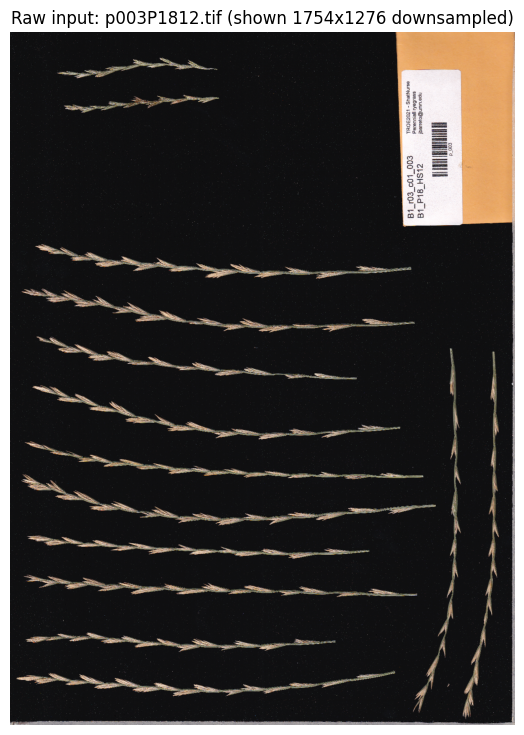

In [ ]:
import matplotlib.pyplot as plt
import skimage.io as sio

img = sio.imread(TIF_PATH)
print("Loaded", TIF_PATH, "shape:", img.shape, "dtype:", img.dtype)

SCANNER_SIZES = {(7016, 5104), (5104, 7016)}
if (img.shape[0], img.shape[1]) in SCANNER_SIZES:
    CROP_COORD = [44, 6940, 25, 4970]   # authors' scanner-margin crop (README §3.2)
    print("Scanner format matches the paper; applying authors' crop", CROP_COORD)
else:
    CROP_COORD = None
    print(f"Size {img.shape[:2]} differs from the paper's 7016x5104; skipping crop (documented adaptation)")

fig, ax = plt.subplots(figsize=(14, 9))
step = max(1, img.shape[0] // 1750)
ax.imshow(img[::step, ::step])
ax.set_title(f"Raw input: {TIF_NAME} (shown {img.shape[0]//step}x{img.shape[1]//step} downsampled)")
ax.axis("off")
plt.show()

## 4. Spike segmentation (authors' `spike_segm`)

We call the authors' `spike_segm` exactly as their driver does: crop (if applicable),
**50% rescale** (the paper's benchmark configuration), then threshold the **red channel
at 25** — inside the paper's reported optimum band of 20–35 for 50%-rescaled images
(RMSE < 1 misdetection per image) and matching the value used for the paper's spikelet
validation. Small objects (≤ n_pixels/10000) are removed by the author function itself.
We then count connected components (the "spikes") and draw the authors' numbered
enumeration overlay (`EnumerateSpkCV`) next to the raw input and the mask. The paper
reports 5–23 spikes per original image; compare the printed count against that range.

*日本語:* 著者の `spike_segm` をそのまま呼び出します（50%リスケール、赤チャネル閾値25 — 論文の最適帯域20–35内）。小物体除去は著者関数内で実行済みです。検出された穂数を表示し、論文の1画像あたり5–23穂という記録と比較してください。

spike_segm took 15.7 s
Rescaled RGB: (3448, 2472, 3) | mask True pixels: 1099130
Detected spikes (connected components): 15
Largest component areas (px): [np.float64(493925.0), np.float64(59862.0), np.float64(56502.0), np.float64(54596.0), np.float64(52122.0)]


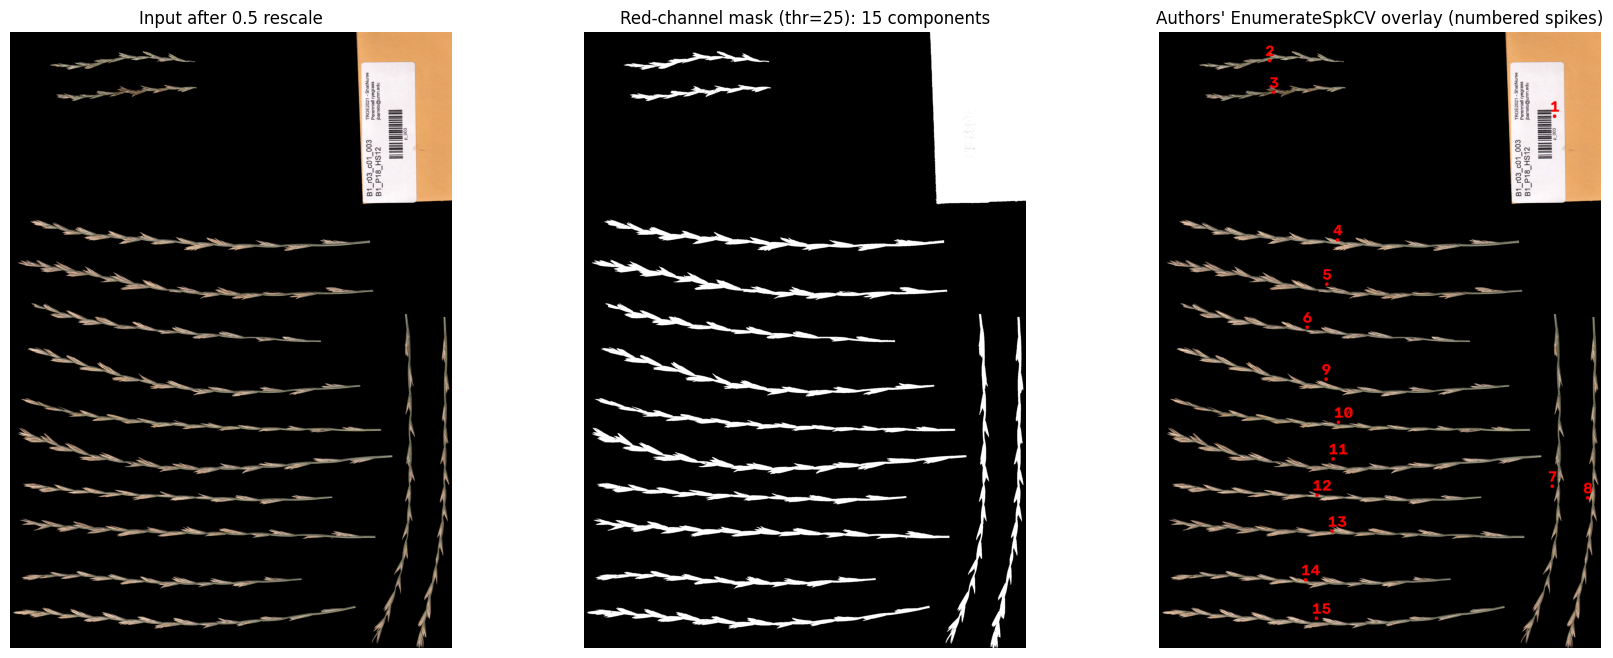

In [ ]:
import time
import numpy as np
import scipy.ndimage as ndi
from skimage.measure import label, regionprops

t0 = time.time()
I = SF.spike_segm(TIF_PATH, rescale_rgb=0.5, channel_thresh=[0, 25], OtsuScaling=0.25,
                  rgb_out=True, gray_out=True, lab_out=True, hsv_out=True, bw_out=True,
                  crop_coord=CROP_COORD)
print(f"spike_segm took {time.time()-t0:.1f} s")
rgb0, gray0, lab0, hsv0, bw0 = I[0], I[1], I[2], I[3], I[4]
print("Rescaled RGB:", rgb0.shape, "| mask True pixels:", int(bw0.sum()))

labeled_spks, num_spikes = label(bw0, return_num=True)
props = regionprops(labeled_spks)
print(f"Detected spikes (connected components): {num_spikes}")
print("Largest component areas (px):", sorted((p.area for p in props), reverse=True)[:5])

Enum_img = SF.EnumerateSpkCV(bw=bw0, rgb=rgb0, Plot=False, PlotOut=True)

fig, axes = plt.subplots(1, 3, figsize=(21, 8))
axes[0].imshow(rgb0);            axes[0].set_title("Input after 0.5 rescale")
axes[1].imshow(bw0, cmap="gray"); axes[1].set_title(f"Red-channel mask (thr=25): {num_spikes} components")
axes[2].imshow(Enum_img);        axes[2].set_title("Authors' EnumerateSpkCV overlay (numbered spikes)")
for a in axes: a.axis("off")
plt.show()

## 5. Spike length — the paper's four methods (authors' `spk_length`)

For each segmented spike we crop the mask exactly as `SpykBatch.py` does and call
`spk_length(..., Method='all', Overlay=False)`, which computes the four paper length
estimates plus per-method timings: bounding-box major axis, convex-hull major axis,
medial axis, and Zhang–Suen skeleton. **Documented label correction:** in the authors'
`spk_length` the result-rename dictionary swaps the two thinning labels — the value
computed with `medial_axis` is written to column `L_skel_Zhang` and the value computed
with `skeletonize` (Zhang–Suen) to `L_skel_ma` (verified against the function body and
an executed diagnostic probe: 1215 vs 446 px on this sample). We keep the authors'
computation untouched and relabel the columns truthfully, recording the original names
in the exported CSV. Lengths are converted to millimeters using the paper's documented
calibration: 600 dpi scanning × 0.5 rescale → 300 px/inch → 25.4/300 mm/px (derived,
clearly labeled). The paper found the medial axis most accurate (R² = 0.96) — for curved
spikes the bounding box / convex hull overestimate length most, which the table makes
visible.

*日本語:* 各穂を著者ドライバと同じ方法で切り出し、`spk_length` の4手法（bbox・凸包・medial axis・Zhang–Suen骨格）で長さを推定します。著者コードの列名辞書は細線化2手法のラベルを入れ替えているため（関数本文と診断プローブで確認）、計算は著者コードのまま列名のみ真実の名前に付け替えます。600 dpi×0.5リスケールから導出した mm/px 変換（派生値）も併記します。

In [ ]:
mm_per_px = 25.4 / (600 * 0.5)  # derived: 600 dpi scanner, 0.5 rescale -> 300 px/inch

rows = []
for lbl in range(1, num_spikes + 1):
    try:
        spk = labeled_spks == lbl
        slice_x, slice_y = ndi.find_objects(spk)[0]
        cropped_spk = spk[slice_x, slice_y]
        L, T = SF.spk_length(cropped_spk, Method="all", Overlay=False)
        row = {"Spike": lbl}
        row.update({c: float(L[c].iloc[0]) for c in L.columns})
        row.update({c: float(T[c].iloc[0]) for c in T.columns})
        rows.append(row)
    except Exception as e:
        print(f"spike {lbl}: length failed ({e})")

lengths_df = pd.DataFrame(rows)
# Truthful relabeling of the authors' swapped thinning column names (see note above);
# the authors' original column names are preserved in the CSV export.
lengths_df = lengths_df.rename(columns={"L_skel_Zhang": "L_medial_axis",
                                        "L_skel_ma": "L_skeleton_ZhangSuen"})
lengths_df["Author_column_of_L_medial_axis"] = "L_skel_Zhang"
lengths_df["Author_column_of_L_skeleton_ZhangSuen"] = "L_skel_ma"
for c in ("L_bbox", "L_chull", "L_medial_axis", "L_skeleton_ZhangSuen"):
    lengths_df[c + "_mm"] = (lengths_df[c] * mm_per_px).round(1)
lengths_df.to_csv("/content/spike_lengths.csv", index=False)
lengths_df

,Spike,L_bbox,L_chull,L_medial_axis,L_skeleton_ZhangSuen,T_bbox,T_chull,T_skel_Zhang,T_skel_ma,Author_column_of_L_medial_axis,Author_column_of_L_skeleton_ZhangSuen,L_bbox_mm,L_chull_mm,L_medial_axis_mm,L_skeleton_ZhangSuen_mm
0,1,1102.0,1105.0,1217.0,446.0,0.04,0.14,0.48,1.37,L_skel_Zhang,L_skel_ma,93.3,93.6,103.0,37.8
1,2,844.0,768.0,739.0,659.0,0.01,0.07,0.17,0.09,L_skel_Zhang,L_skel_ma,71.5,65.0,62.6,55.8
2,3,860.0,785.0,670.0,685.0,0.01,0.06,0.14,0.06,L_skel_Zhang,L_skel_ma,72.8,66.5,56.7,58.0
3,4,2074.0,1849.0,1841.0,1803.0,0.01,0.16,0.24,0.15,L_skel_Zhang,L_skel_ma,175.6,156.5,155.9,152.7
4,5,2199.0,1881.0,2045.0,1871.0,0.02,0.17,0.27,0.29,L_skel_Zhang,L_skel_ma,186.2,159.3,173.1,158.4
5,6,1770.0,1596.0,1553.0,1481.0,0.02,0.21,0.34,0.26,L_skel_Zhang,L_skel_ma,149.9,135.1,131.5,125.4
6,7,2169.0,1774.0,1814.0,1743.0,0.03,0.26,0.38,0.28,L_skel_Zhang,L_skel_ma,183.6,150.2,153.6,147.6
7,8,2180.0,1791.0,1823.0,1755.0,0.02,0.22,0.38,0.15,L_skel_Zhang,L_skel_ma,184.6,151.6,154.3,148.6
8,9,2057.0,1728.0,1876.0,1736.0,0.02,0.19,0.28,0.18,L_skel_Zhang,L_skel_ma,174.2,146.3,158.8,147.0
9,10,2202.0,1928.0,2037.0,1889.0,0.01,0.16,0.25,0.17,L_skel_Zhang,L_skel_ma,186.4,163.2,172.5,159.9


### Length overlay for one spike (authors' medial-axis visualization)

`spk_length(..., Overlay=True)` draws the medial-axis skeleton over the spike mask (the
authors' own visualization). About the returned number: the authors' Overlay return path
always returns `Length_data[0]`, which is the value computed by whichever method block
ran — for the `Method='skel_ma'` call used here, only the medial-axis block runs, so the
returned 1225 px is that call's **medial-axis** count. It matches the table's medial-axis
value for Spike 1 (1217 px) within the few-pixel variation that `skimage.medial_axis`
introduces through its documented random tie-breaking. (With `Method='all'`,
`Length_data[0]` would instead be the bounding-box value.) The spike shown is the
representative `Spike == 1` from the table above, not a selected showcase.

*日本語:* `spk_length` の Overlay 機能で medial axis スケルトンをマスク上に重ねて表示します（著者実装）。戻り値は著者関数の `Length_data[0]`、すなわちここでは `Method='skel_ma'` で実行された medial axis の値（1225 px）であり、表の medial axis 値（1217 px）と `medial_axis` のランダムタイブレーク由来の数px以内で一致します。

Spike 1: value returned by spk_length(Overlay=True) = 1225 px (= Length_data[0], the bounding-box major axis)
Spike 1 medial-axis length from the table = 1217 px = 103.0 mm


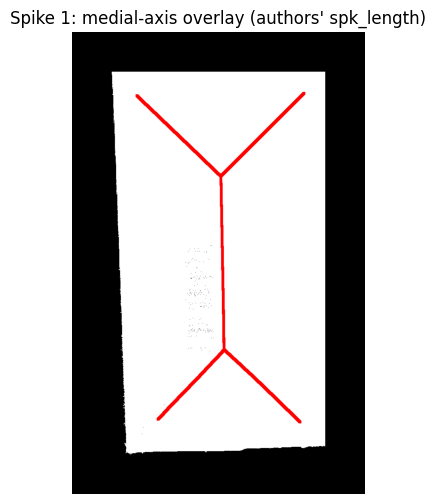

In [ ]:
spk1 = labeled_spks == 1
sx, sy = ndi.find_objects(spk1)[0]
sl, length_img = SF.spk_length(spk1[sx, sy], Method="skel_ma", Overlay=True)
print(f"Spike 1: value returned by spk_length(Overlay=True) = {sl} px "
      f"(= Length_data[0], the bounding-box major axis)")
print(f"Spike 1 medial-axis length from the table = {lengths_df.loc[0, 'L_medial_axis']:.0f} px "
      f"= {lengths_df.loc[0, 'L_medial_axis'] * mm_per_px:.1f} mm")

plt.figure(figsize=(5, 6))
plt.imshow(length_img)
plt.title("Spike 1: medial-axis overlay (authors' spk_length)")
plt.axis("off")
plt.show()

## 6. Spikelet counting — distance-transform watershed (authors' `spikelet_segm`)

Per spike, the masked RGB crop is passed to the authors' `spikelet_segm` with their
defaults (`Pad=200`) and `MinDist=25`: the paper swept minimum distances of 25–75 px on
50%-rescaled images and 25 px gave the best agreement with manual counts (1.98 ± 1.64
misdetections, Pearson r = 0.78). The function fits an ellipse per spikelet and returns
per-spikelet geometry; we record the count per spike and show the authors' numbered
ellipse overlay for the first successfully processed spike.

*日本語:* 各穂のRGBクロップを著者の `spikelet_segm`（Pad=200、MinDist=25 — 論文のスイープで最良の25 px）に渡し、小穂数を計数します。最初に成功した穂の楕円オーバーレイを表示します。

In [ ]:
MIN_DIST = 25
spikelet_rows = []
first_overlay = None

for lbl in range(1, num_spikes + 1):
    try:
        spk = labeled_spks == lbl
        slice_x, slice_y = ndi.find_objects(spk)[0]
        cropped_rgb = rgb0[slice_x, slice_y]
        cropped_rgb = np.where(spk[slice_x, slice_y][..., None], cropped_rgb, 0)
        Spikelets, EllipseData, Spikelets_Image = SF.spikelet_segm(
            cropped_rgb=cropped_rgb, Pad=200, MinDist=MIN_DIST, data_out=True,
            plot_ellipse=True, Numbered=True, img_out=True, plot_segmented=False)
        spikelet_rows.append({"Spike": lbl,
                              "Spikelets": len(EllipseData),
                              "Mean_ellipse_length_px": float(EllipseData["Ellipse_Length"].mean())})
        if first_overlay is None:
            first_overlay, first_lbl = Spikelets_Image, lbl
    except Exception as e:
        print(f"spike {lbl}: spikelet segmentation failed ({e})")

spikelets_df = pd.DataFrame(spikelet_rows)
print(f"MinDist={MIN_DIST} px; spikelets counted for {len(spikelets_df)}/{num_spikes} spikes")
spikelets_df

spike 6: spikelet segmentation failed (OpenCV(5.0.0) /io/opencv/modules/geometry/src/shapedescr.cpp:261: error: (-201:Incorrect size of input array) There should be at least 5 points to fit the ellipse in function 'fitEllipseNoDirect'
)


spike 13: spikelet segmentation failed (OpenCV(5.0.0) /io/opencv/modules/geometry/src/shapedescr.cpp:261: error: (-201:Incorrect size of input array) There should be at least 5 points to fit the ellipse in function 'fitEllipseNoDirect'
)


MinDist=25 px; spikelets counted for 13/15 spikes


,Spike,Spikelets,Mean_ellipse_length_px
0,1,6,1047.833333
1,2,11,87.181818
2,3,11,76.727273
3,4,20,114.700000
4,5,23,105.608696
5,7,17,130.764706
6,8,19,102.368421
7,9,22,103.545455
8,10,25,102.920000
9,11,20,119.550000


The overlay below is the authors' own output image (`spikelet_segm` with
`plot_ellipse=True, Numbered=True`): each detected spikelet is drawn as a random-colored
ellipse with its major axis and index number, on the padded spike crop.

*日本語:* 下図は著者実装の出力画像そのものです。検出された小穂ごとに楕円（長軸と番号付き）が描画されます。

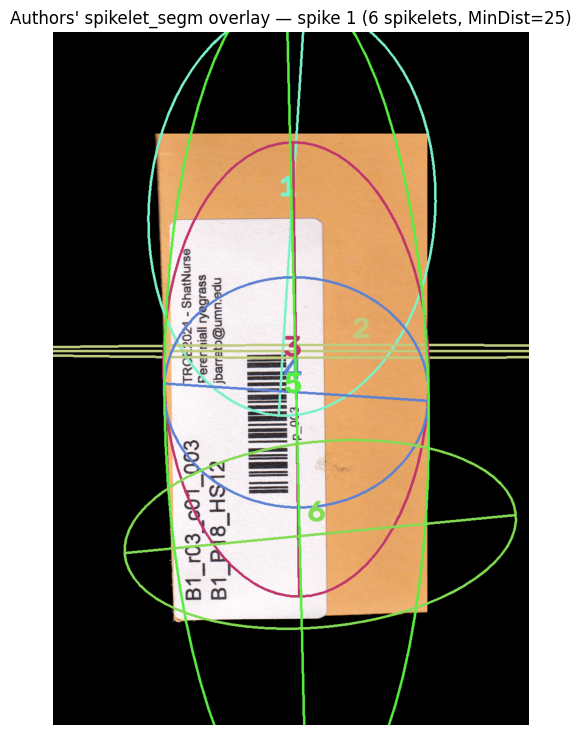

In [ ]:
if first_overlay is not None:
    fig, ax = plt.subplots(figsize=(8, 9))
    ax.imshow(first_overlay)
    ax.set_title(f"Authors' spikelet_segm overlay — spike {first_lbl} "
                 f"({int(spikelets_df.loc[spikelets_df['Spike'] == first_lbl, 'Spikelets'].iloc[0])} spikelets, MinDist={MIN_DIST})")
    ax.axis("off")
    plt.show()
else:
    print("No spike produced a spikelet overlay (all failed — see messages above).")

## 7. Results summary, export, and an additional view

We merge per-spike lengths and spikelet counts into one table (the notebook's
quantitative result) and offer a CSV export inside Colab. The grouped bar chart is an
**additional visualization created for this notebook** (not an author figure): it makes
the paper's qualitative finding — thinning-based lengths (skeleton, medial axis) track
the true spike contour while bounding box/convex hull overshoot — visible for this
sample.

*日本語:* 穂ごとの長さ（4手法）と小穂数を1つの表にまとめ、CSVとして保存できます。棒グラフは本ノートブック用に追加作成した可視化であり（著者の図ではない）、細線化系の長さ推定が輪郭に沿う一方、bbox・凸包が過大評価になる傾向を示します。

In [ ]:
results_df = lengths_df.merge(spikelets_df, on="Spike", how="left")
results_df.to_csv("/content/spykprops_one_image_results.csv", index=False)
print(f"Saved /content/spykprops_one_image_results.csv ({len(results_df)} spikes)")
results_df

Saved /content/spykprops_one_image_results.csv (15 spikes)


,Spike,L_bbox,L_chull,L_medial_axis,L_skeleton_ZhangSuen,T_bbox,T_chull,T_skel_Zhang,T_skel_ma,Author_column_of_L_medial_axis,Author_column_of_L_skeleton_ZhangSuen,L_bbox_mm,L_chull_mm,L_medial_axis_mm,L_skeleton_ZhangSuen_mm,Spikelets,Mean_ellipse_length_px
0,1,1102.0,1105.0,1217.0,446.0,0.04,0.14,0.48,1.37,L_skel_Zhang,L_skel_ma,93.3,93.6,103.0,37.8,6.0,1047.833333
1,2,844.0,768.0,739.0,659.0,0.01,0.07,0.17,0.09,L_skel_Zhang,L_skel_ma,71.5,65.0,62.6,55.8,11.0,87.181818
2,3,860.0,785.0,670.0,685.0,0.01,0.06,0.14,0.06,L_skel_Zhang,L_skel_ma,72.8,66.5,56.7,58.0,11.0,76.727273
3,4,2074.0,1849.0,1841.0,1803.0,0.01,0.16,0.24,0.15,L_skel_Zhang,L_skel_ma,175.6,156.5,155.9,152.7,20.0,114.700000
4,5,2199.0,1881.0,2045.0,1871.0,0.02,0.17,0.27,0.29,L_skel_Zhang,L_skel_ma,186.2,159.3,173.1,158.4,23.0,105.608696
5,6,1770.0,1596.0,1553.0,1481.0,0.02,0.21,0.34,0.26,L_skel_Zhang,L_skel_ma,149.9,135.1,131.5,125.4,NaN,NaN
6,7,2169.0,1774.0,1814.0,1743.0,0.03,0.26,0.38,0.28,L_skel_Zhang,L_skel_ma,183.6,150.2,153.6,147.6,17.0,130.764706
7,8,2180.0,1791.0,1823.0,1755.0,0.02,0.22,0.38,0.15,L_skel_Zhang,L_skel_ma,184.6,151.6,154.3,148.6,19.0,102.368421
8,9,2057.0,1728.0,1876.0,1736.0,0.02,0.19,0.28,0.18,L_skel_Zhang,L_skel_ma,174.2,146.3,158.8,147.0,22.0,103.545455
9,10,2202.0,1928.0,2037.0,1889.0,0.01,0.16,0.25,0.17,L_skel_Zhang,L_skel_ma,186.4,163.2,172.5,159.9,25.0,102.920000


The chart below compares the four length estimates per spike in millimeters (the CSV's
`*_mm` columns, derived from the 600-dpi calibration; thinning columns use the truthful
relabeling explained in section 5). For straight spikes all four agree; diverging bars
identify curved spikes where the bounding box and convex hull overshoot — the paper's
motivation for thinning-based estimators.

*日本語:* 下の棒グラフは、600 dpi校正から変換した4手法の穂長（mm）を穂ごとに比較します（細線化列は第5節で説明した真実の列名）。曲がった穂では bbox・凸包が過大評価になる様子が読み取れます。

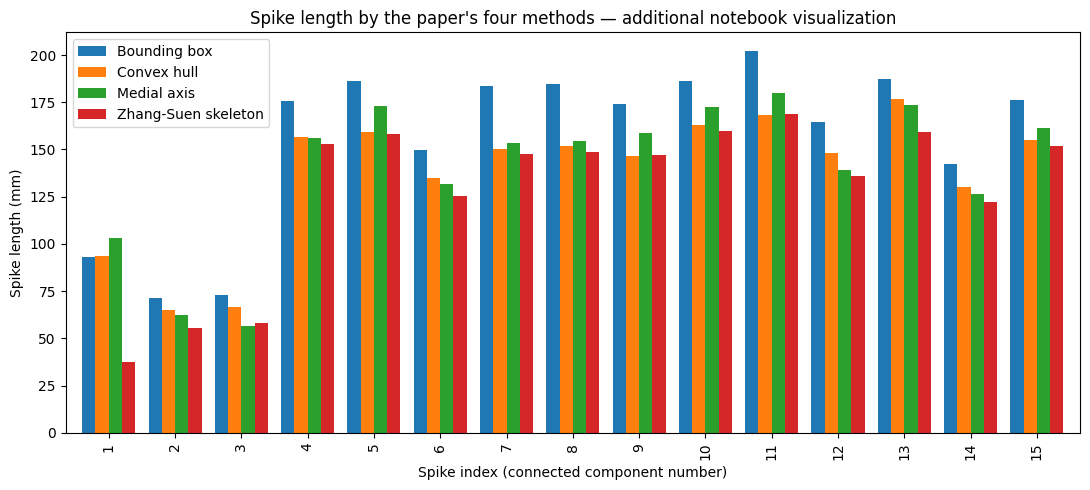

In [ ]:
ax = results_df.plot(x="Spike",
                     y=["L_bbox_mm", "L_chull_mm", "L_medial_axis_mm", "L_skeleton_ZhangSuen_mm"],
                     kind="bar", figsize=(11, 5), width=0.8)
ax.set_xlabel("Spike index (connected component number)")
ax.set_ylabel("Spike length (mm)")
ax.set_title("Spike length by the paper's four methods — additional notebook visualization")
ax.legend(["Bounding box", "Convex hull", "Medial axis", "Zhang-Suen skeleton"])
plt.tight_layout()
plt.show()

## 8. Interpretation and limitations

**What this run shows.** The printed outputs demonstrate the paper's core pipeline end
to end on one original dataset image: red-channel segmentation after 0.5 rescale, four
length estimators with the medial axis behaving as reported (least overshoot), and
distance-transform watershed spikelet counts with per-spikelet ellipse geometry. Compare
the printed spike count with the paper's documented 5–23 spikes per image, and the
per-method length spread with the paper's qualitative account (medial axis R² = 0.96
against manual ImageJ measurements).

**Limitations.** A single image cannot verify the paper's dataset-level accuracy
(RMSE < 1 misdetections on 2743 spikes; spikelet r = 0.78 on 793 spikes) — no manual
ground truth for this scan is part of the published dataset. The exact correspondence
between dataset members and the paper's 166 scans is not documented; the sample was
chosen by the fixed first-`.tif` rule above. Two quirks of the authors' `spk_length`
were found during this reproduction and are documented in section 5 (swapped thinning
column labels; the Overlay return path always returning `Length_data[0]`, which is the
bounding-box value only when `Method='all'`) — the computations themselves are the
authors', unchanged. EFD/color descriptors, Euclidean-distance
matrices, and the caret ML phases (which would need the 20-family nursery trait table
and the paper's unspecified family split) are out of scope.

*日本語:* 本実行は1枚の画像による部分デモであり、論文のデータセット全体精度（RMSE<1、r=0.78など）の検証ではありません。手動測定の正解データは公開データセットに含まれないため、自動値と手動値の定量比較はできません。記述子抽出・機械学習フェーズは対象外です。

## 9. Provenance and references

- Paper: doi:10.1186/s13007-023-01104-z, PMCID PMC10644492 (publisher version).
- Code: `github.com/joanmanbar/SpykProps` @ `19e8f6ef8c6cdd52f416a9d3ed91b4ce99099b5c`,
  `SpykFunctions.py` git-blob `e1f3ea77f7940c2dc6e0fc7508a2f9827c9ec272` (verified above);
  driver logic replicated from `SpykBatch.py`. Repository has no LICENSE file; author
  code is used with attribution for reproduction.
- Data: hdl:11299/256105, UMN Conservancy item `e57378f2-0004-4ed1-ad65-165b263dbc3e`,
  CC0 1.0, accessed via the public DSpace REST API; sample extracted by HTTP range
  requests (SHA-256 printed above).
- Parameter provenance: 0.5 rescale and red-channel 20–35 band (paper Results,
  Spike segmentation); MinDist=25 px (paper Results, Spikelet segmentation); crop and
  Pad=200 (author README/driver).
- PhenoPaper investigation `p-b1ad16e5699a826bc924207af4593ec7-20260930T140256Z-3710427`
  was used as prior research guidance; all parameters above were re-verified against the
  pinned code and the study flow's cited paper locators.
